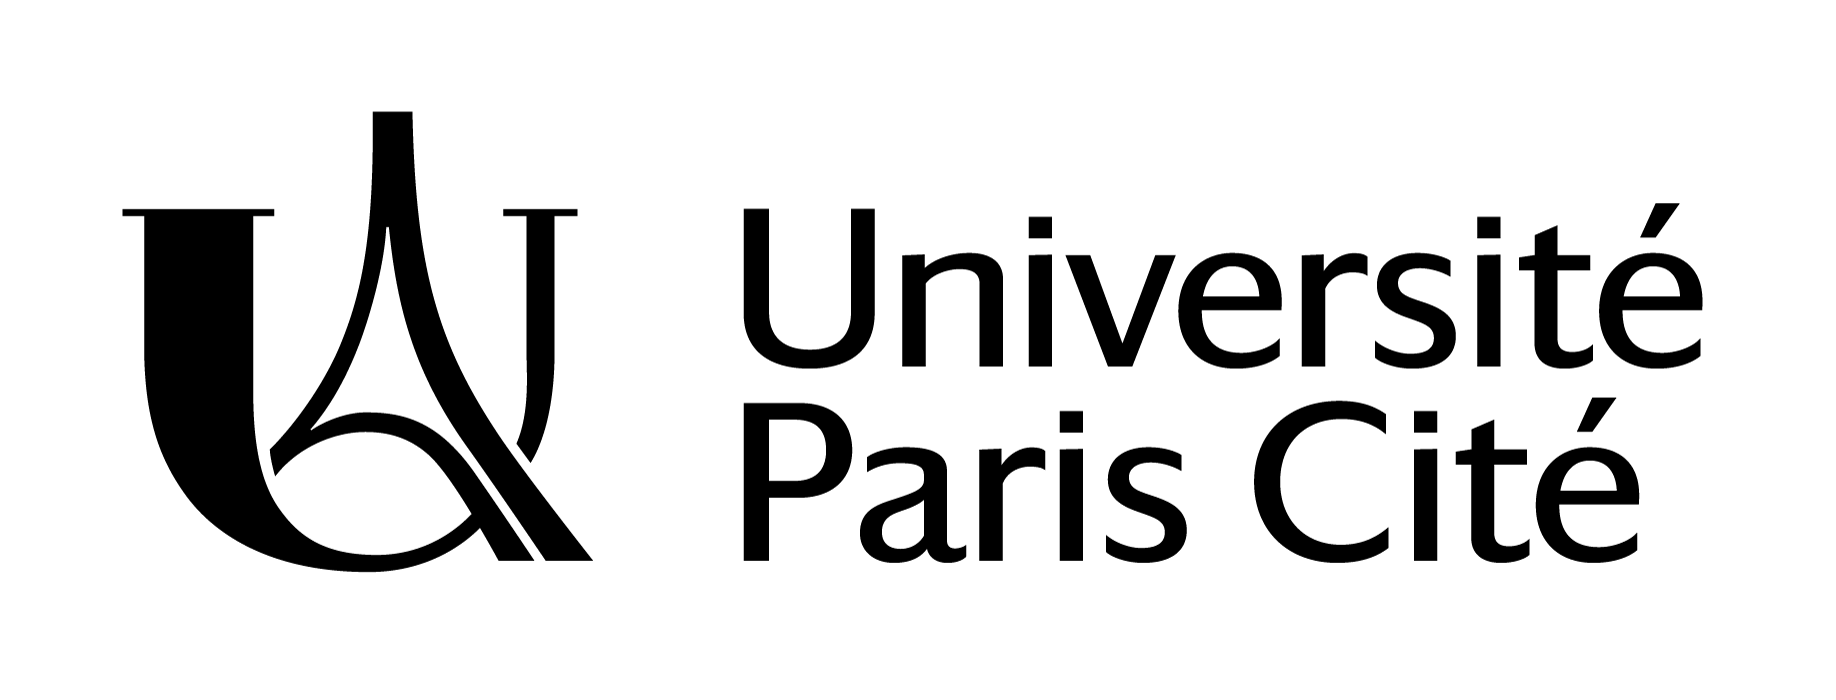



# M2 VMI - TP GenAI: Catch them all (and more)

You can choose to do this lab on either a Google Colab instance, or locally. If you do it on a Colab instance, make sure to activate the GPU.

Images: © Nintendo/Game Freak.

Exercises after d2l.ai

## 1) Loading the data
Let's get all of the data required for this lab.


**Kaggle:** activate a GPU accelerator and Internet for the dataset download. The VAE uses pixels in [0, 1] and the GAN uses pixels in [-1, 1]. Batch size is reduced to 128 to limit GPU memory.

In [7]:
from pathlib import Path
import urllib.request
import zipfile

if not Path('pokemon/25').is_dir():
    url = 'https://d2l-data.s3-accelerate.amazonaws.com/pokemon.zip'
    if not Path('pokemon.zip').exists():
        urllib.request.urlretrieve(url, 'pokemon.zip')
    with zipfile.ZipFile('pokemon.zip') as archive:
        archive.extractall('.')
print('Dataset ready')


Dataset ready


As you might have guessed, we will look at pokemons (the data is from https://pokemondb.net/sprites)

For some of them, you even have several sprites that form an animation!

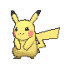

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from pathlib import PurePath

# List of image filenames
filenames = [str(PurePath('pokemon', '25', f'25-{i}.png')) for i in range(33)]

fig, ax = plt.subplots(figsize=(0.64, 0.64), dpi=100)
img = mpimg.imread(filenames[0])
im = ax.imshow(img)
ax.axis('off')

def update(frame):
    img = mpimg.imread(filenames[frame])
    im.set_array(img)
    return [im]

ani = FuncAnimation(fig, update, frames=len(filenames), interval=60, blit=True)

# Display the animation as an HTML5 video in Colab
HTML(ani.to_jshtml())

Load the dataset, and vizualize a few samples:

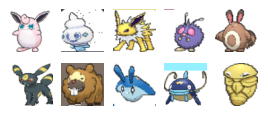

In [9]:
import warnings
import torch
import torchvision
from torch import nn

pokemon = torchvision.datasets.ImageFolder('pokemon')
batch_size = 128
transformer = torchvision.transforms.Compose([
    torchvision.transforms.Resize((64, 64)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(0.5, 0.5)
])
pokemon.transform = transformer
data_iter = torch.utils.data.DataLoader(
    pokemon, batch_size=batch_size,
    shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())

warnings.filterwarnings('ignore')
num_rows = 2
num_cols = 5
fig, axes = plt.subplots(num_rows, num_cols, figsize=(0.64*num_cols, 0.64*num_rows), dpi=100)
for X, y in data_iter:
    imgs = X[:num_rows * num_cols,:,:,:].permute(0, 2, 3, 1)/2+0.5
    for img_index, img in enumerate(imgs):
      axes[img_index//num_cols, img_index%num_cols].imshow(img)
      axes[img_index//num_cols, img_index%num_cols].axis('off')
    break

In [10]:
# Reproducible split by Pokémon folder (rather than individual sprite).
import random, numpy as np, pandas as pd
from torch.utils.data import DataLoader, Subset
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
classes = np.unique(pokemon.targets)
rng = np.random.default_rng(SEED)
classes = rng.permutation(classes)
n_val = max(1, int(0.2 * len(classes)))
val_classes = set(classes[:n_val])
train_idx = [i for i,y in enumerate(pokemon.targets) if y not in val_classes]
val_idx = [i for i,y in enumerate(pokemon.targets) if y in val_classes]
assert train_idx and val_idx
# Both models use the same split.
data_iter = DataLoader(Subset(pokemon, train_idx), batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
val_iter = DataLoader(Subset(pokemon, val_idx), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
print(f'Train: {len(train_idx)} | Held-out: {len(val_idx)}')


Train: 32469 | Held-out: 8128


Finally, let's add a few functions that will be helping us down the road.

In [11]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

def try_gpu():
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class Timer:
    def __init__(self):
        self.start_time = None
        self.total_time = 0
    def start(self):
        self.start_time = time.time()
    def stop(self):
        if self.start_time is None:
            return 0
        self.total_time += time.time() - self.start_time
        self.start_time = None
        return self.total_time

class Accumulator:
    """Accumulate sums over n variables."""
    def __init__(self, n):
        self.data = [0.0] * n
    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    def reset(self):
        self.data = [0.0] * len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

In [12]:
# Image quality metrics (Kaggle Internet needed for pretrained Inception weights).
%pip -q install torchmetrics torch-fidelity


Note: you may need to restart the kernel to use updated packages.


In [13]:
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.functional.image import structural_similarity_index_measure
import time
from pathlib import Path
OUT = Path('pokemon_results'); OUT.mkdir(exist_ok=True)
device = try_gpu()
# Fixed held-out reference and fixed noise for fair comparisons across epochs.
EVAL_N = min(512, len(val_idx))
assert EVAL_N >= 2
EVAL_EVERY = 5
ref_loader = DataLoader(Subset(pokemon, val_idx[:EVAL_N]), batch_size=32, shuffle=False)
ref_images = torch.cat([x for x,_ in ref_loader]).mul(0.5).add(0.5)
fid_metric = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)
kid_metric = KernelInceptionDistance(feature=2048, normalize=True, subset_size=min(50,EVAL_N), subsets=10, reset_real_features=False).to(device)
for x in ref_images.split(32):
    fid_metric.update(x.to(device), real=True)
    kid_metric.update(x.to(device), real=True)
@torch.no_grad()
def generation_scores(model, kind, z):
    model.eval()
    for batch in z.split(32):
        x = model.decode(batch) if kind == 'VAE' else model(batch).mul(0.5).add(0.5)
        x = x.clamp(0,1)
        fid_metric.update(x, real=False); kid_metric.update(x, real=False)
    fid = fid_metric.compute().item(); mean, std = kid_metric.compute()
    fid_metric.reset(); kid_metric.reset()
    return fid, mean.item(), std.item()

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def plot_history(df, groups, name):
    for columns in groups:
        fig, ax = plt.subplots(figsize=(7,4))
        for col in columns:
            if col in df:
                d = df.dropna(subset=[col]); ax.plot(d.epoch, d[col], 'o-', label=col)
        ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(OUT / (name+'_'+columns[0]+'.png'), dpi=150); plt.show(); plt.close(fig)


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 416MB/s]


## Part 1 - VAE
### 1.1 Defining the architecture
We will create a simple architecture for our auto-encoder.

In [14]:
# Define the VAE model
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=128):
        super(ConvVAE, self).__init__()
        self.latent_dim = latent_dim

        # Encoder: 3x64x64 input RGB images
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),  # 32x32x32
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),  # 64x16x16
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1),  # 128x8x8
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1),  # 256x4x4
            nn.ReLU(),
        )

        self.fc_mu = nn.Linear(256*4*4, latent_dim)
        self.fc_logvar = nn.Linear(256*4*4, latent_dim)

        # Decoder
        self.fc_decoder = nn.Linear(latent_dim, 256*4*4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),  # 128x8x8
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 64x16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),  # 32x32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),  # 3x64x64
            nn.Sigmoid(),  # Output in [0,1]
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_decoder(z)
        h = h.view(h.size(0), 256, 4, 4)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar

### 1.2 Training loop


Finally, we can define the training loop. Here you will need to fill the parts maked as

```
## TO COMPLETE ##
```

{'epoch': 1, 'train_loss': np.float64(716.6363201727032), 'train_recon': np.float64(692.7357801864856), 'train_kl': np.float64(23.900539563163978), 'train_seconds': 13.516663474999973, 'images_sec': 2402.146066597997, 'val_loss': np.float64(555.5382284329633), 'val_recon': np.float64(518.7400224340244), 'val_kl': np.float64(36.798203415758024), 'mse': np.float64(0.0399893151933518), 'psnr': np.float64(14.241590912886492), 'ssim': np.float64(0.3481048580229752)}
{'epoch': 2, 'train_loss': np.float64(473.7925757068281), 'train_recon': np.float64(426.5219219919385), 'train_kl': np.float64(47.27065437657843), 'train_seconds': 13.565900567999961, 'images_sec': 2393.427538204856, 'val_loss': np.float64(452.40545149675506), 'val_recon': np.float64(400.6663400244525), 'val_kl': np.float64(51.73910681656965), 'mse': np.float64(0.03032980983944859), 'psnr': np.float64(15.415608158261756), 'ssim': np.float64(0.4137068911800234)}
{'epoch': 3, 'train_loss': np.float64(385.6367828135106), 'train_rec

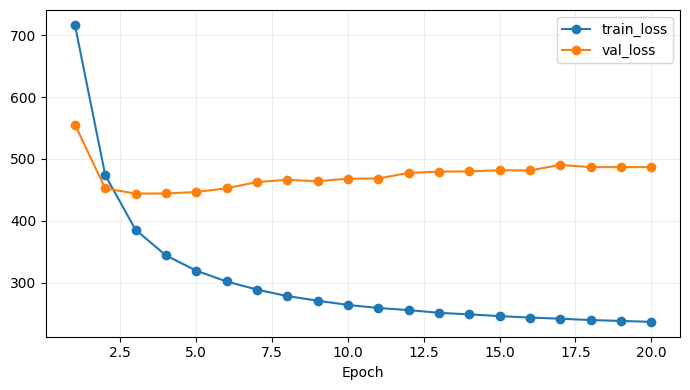

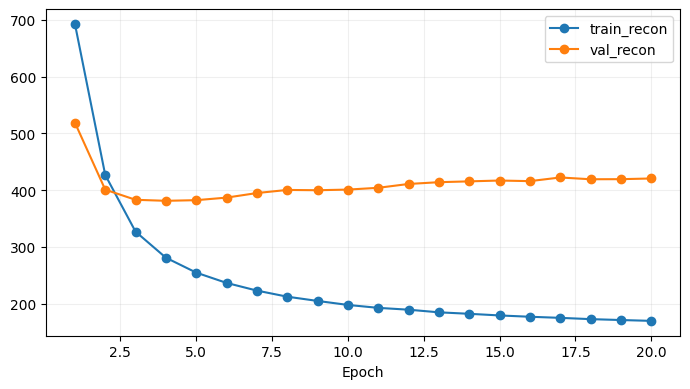

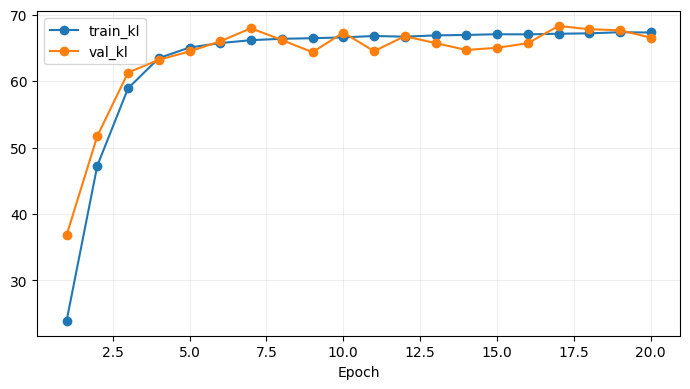

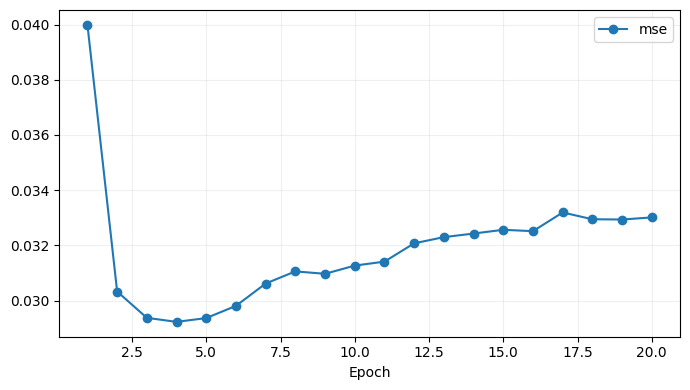

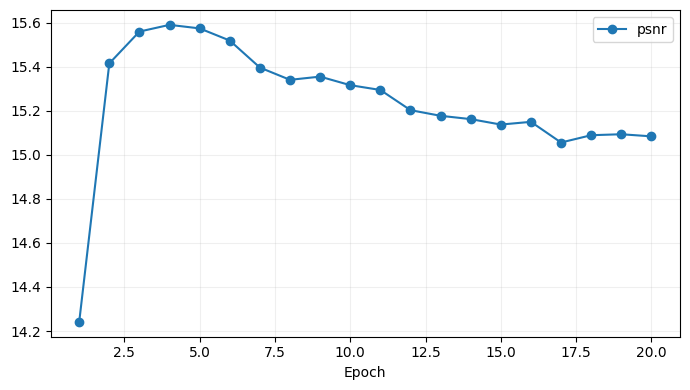

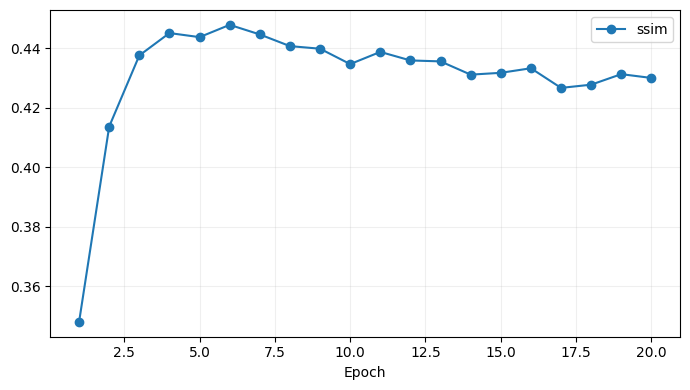

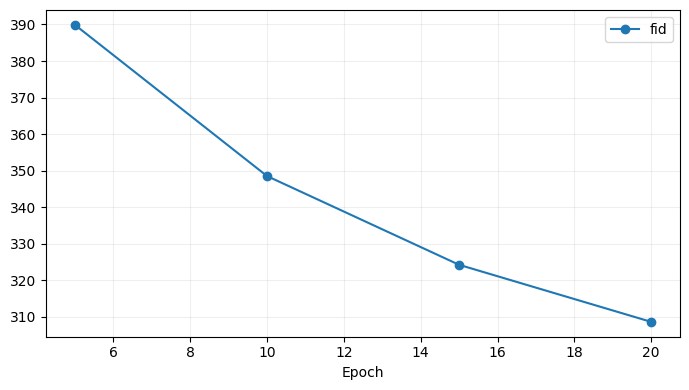

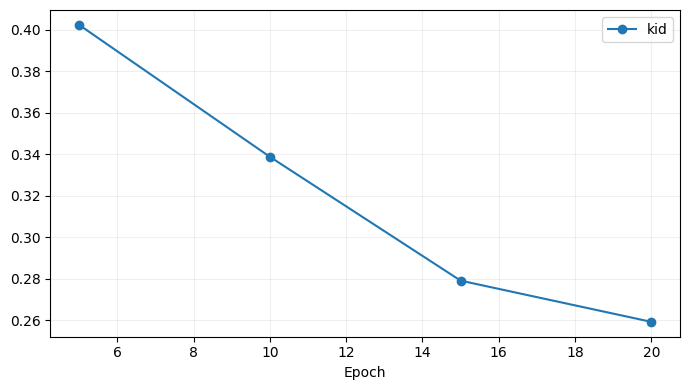

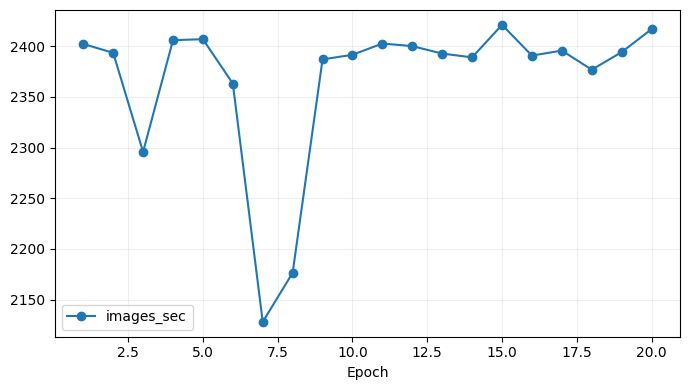

In [15]:
import torch.nn.functional as F

def vae_loss(recon, x, mu, logvar):
    mse = F.mse_loss(recon, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp())
    return mse + kl, mse, kl

@torch.no_grad()
def evaluate_vae(model):
    model.eval(); sums = np.zeros(6); count = 0
    for X,_ in val_iter:
        X = X.to(device).mul(.5).add(.5)
        recon, mu, logvar = model(X)
        loss, rec, kl = vae_loss(recon,X,mu,logvar)
        # Deterministic reconstruction using posterior mean for image metrics.
        pred = model.decode(mu)
        mse = (pred-X).square().flatten(1).mean(1)
        psnr = -10*torch.log10(mse.clamp_min(1e-12))
        ssim = structural_similarity_index_measure(pred, X, data_range=1., reduction='none')
        sums += [loss.item(), rec.item(), kl.item(), mse.sum().item(), psnr.sum().item(), ssim.sum().item()]
        count += len(X)
    return dict(zip(['val_loss','val_recon','val_kl','mse','psnr','ssim'], sums/count))

vae = ConvVAE(latent_dim=128).to(device)
num_epochs = 20
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_z = torch.randn(EVAL_N, vae.latent_dim, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
vae_rows = []
for epoch in range(1,num_epochs+1):
    vae.train(); sums = np.zeros(3); count=0; sync(); start=time.perf_counter()
    for X,_ in data_iter:
        X = X.to(device).mul(.5).add(.5)
        optimizer.zero_grad(); recon,mu,logvar = vae(X)
        loss,rec,kl = vae_loss(recon,X,mu,logvar)
        loss.backward(); optimizer.step()
        sums += [loss.item(),rec.item(),kl.item()]; count += len(X)
    sync(); elapsed=time.perf_counter()-start
    row = dict(epoch=epoch, **dict(zip(['train_loss','train_recon','train_kl'],sums/count)), train_seconds=elapsed, images_sec=count/elapsed)
    row.update(evaluate_vae(vae))
    if epoch % EVAL_EVERY == 0 or epoch == num_epochs:
        row.update(zip(['fid','kid','kid_std'],generation_scores(vae,'VAE',vae_z)))
    vae_rows.append(row); vae_history=pd.DataFrame(vae_rows)
    vae_history.to_csv(OUT/'vae_history.csv',index=False)
    print(row)
    torch.save(vae.state_dict(), OUT/'vae_latest.pth')
plot_history(vae_history,[['train_loss','val_loss'],['train_recon','val_recon'],['train_kl','val_kl'],['mse'],['psnr'],['ssim'],['fid'],['kid'],['images_sec']], 'vae')


### 1.3 Inference
Finally, let's do the inference on our exemples

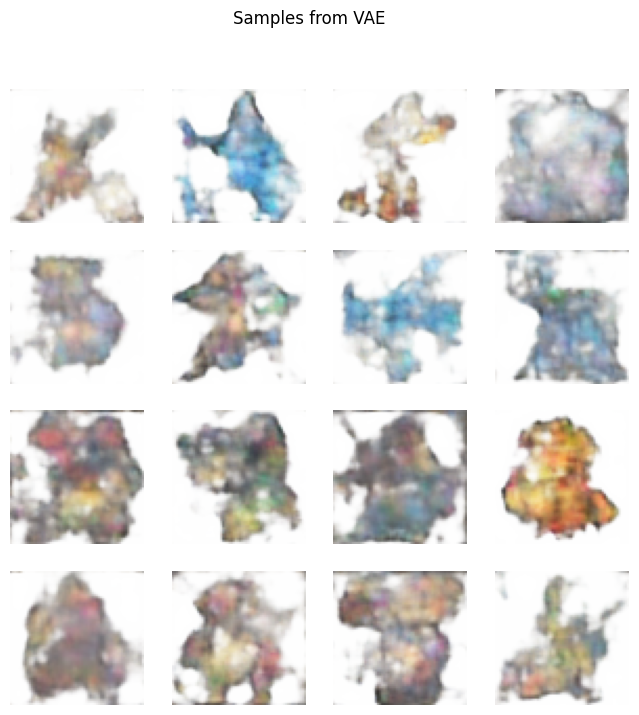

In [16]:
import matplotlib.pyplot as plt
import torch

def sample_vae(model, num_samples=16, latent_dim=128, device='cpu'):
    model.eval()
    with torch.no_grad():
        # Sample latent vectors from standard normal distribution
        z = torch.randn(num_samples, latent_dim, device=device)
        # Decode to image space
        samples = model.decode(z).cpu()

        # Plot samples in a grid
        grid_size = int(num_samples**0.5)
        fig, axes = plt.subplots(grid_size, grid_size, figsize=(grid_size*2, grid_size*2))
        for i, ax in enumerate(axes.flatten()):
            img = samples[i].permute(1, 2, 0)  # CHW to HWC
            ax.imshow(img)
            ax.axis('off')
        plt.suptitle('Samples from VAE')
        plt.show()

sample_vae(vae, num_samples=16, latent_dim=vae.latent_dim, device=device)

## Part 2: GAN
### 2.1 GAN model - generator
Let's create a very simple generator, doing a series of 4 convolutions, and one transposed convolution.

In [17]:
class G_block(nn.Module):
    def __init__(self, out_channels, in_channels=3, kernel_size=4, strides=2,
                 padding=1, **kwargs):
        super(G_block, self).__init__(**kwargs)
        self.conv2d_trans = nn.ConvTranspose2d(in_channels, out_channels,
                                kernel_size, strides, padding, bias=False)
        self.batch_norm = nn.BatchNorm2d(out_channels)
        self.activation = nn.ReLU()

    def forward(self, X):
        return self.activation(self.batch_norm(self.conv2d_trans(X)))

n_G = 64
net_G = nn.Sequential(
    G_block(in_channels=100, out_channels=n_G*8,
            strides=1, padding=0),                  # Output: (64 * 8, 4, 4)
    G_block(in_channels=n_G*8, out_channels=n_G*4), # Output: (64 * 4, 8, 8)
    G_block(in_channels=n_G*4, out_channels=n_G*2), # Output: (64 * 2, 16, 16)
    G_block(in_channels=n_G*2, out_channels=n_G),   # Output: (64, 32, 32)
    nn.ConvTranspose2d(in_channels=n_G, out_channels=3,
                       kernel_size=4, stride=2, padding=1, bias=False),
    nn.Tanh())

### 2.2 GAN model - discriminator
We can now define a discriminator as a mirror of the generator:

In [18]:
class D_block(nn.Module):
    def __init__(self, out_channels, in_channels=3, kernel_size=4, strides=2,
                padding=1, alpha=0.2, **kwargs):
        super(D_block, self).__init__(**kwargs)
        self.conv2d = nn.Conv2d(in_channels, out_channels, kernel_size,
                                strides, padding, bias=False)
        self.batch_norm = nn.BatchNorm2d(out_channels)
        self.activation = nn.LeakyReLU(alpha, inplace=True)

    def forward(self, X):
        return self.activation(self.batch_norm(self.conv2d(X)))

n_D = 64
net_D = nn.Sequential(
    D_block(n_D),  # Output: (64, 32, 32)
    D_block(in_channels=n_D, out_channels=n_D*2),  # Output: (64 * 2, 16, 16)
    D_block(in_channels=n_D*2, out_channels=n_D*4),  # Output: (64 * 4, 8, 8)
    D_block(in_channels=n_D*4, out_channels=n_D*8),  # Output: (64 * 8, 4, 4)
    nn.Conv2d(in_channels=n_D*8, out_channels=1,
              kernel_size=4, bias=False))  # Output: (1, 1, 1)

### 2.3 Training loop
We can now train our model on the pokemon dataset

Finally, we can define the training loop. Here you will need to fill the parts maked as

```
## TO COMPLETE ##
```

In [19]:
def update_D(X, Z, net_D, net_G, loss_fn, trainer_D):
    # Forward real images
    batch_size = X.shape[0]
    real_labels = torch.ones(batch_size, device=X.device)
    fake_labels = torch.zeros(batch_size, device=X.device)

    trainer_D.zero_grad()

    # Real images
    outputs_real = net_D(X).reshape(-1)
    loss_real = loss_fn(outputs_real, real_labels)
    loss_real.backward()

    # Fake images
    fake_images = net_G(Z).detach()
    outputs_fake = net_D(fake_images).reshape(-1)
    loss_fake = loss_fn(outputs_fake, fake_labels)
    loss_fake.backward()

    trainer_D.step()

    correct = (outputs_real >= 0).sum().item() + (outputs_fake < 0).sum().item()
    return (loss_real + loss_fake).item(), correct

def update_G(Z, net_D, net_G, loss_fn, trainer_G):
    batch_size = Z.shape[0]
    real_labels = torch.ones(batch_size, device=Z.device)

    net_D.requires_grad_(False)
    trainer_G.zero_grad()
    fake_images = net_G(Z)
    outputs = net_D(fake_images).reshape(-1)
    loss_G = loss_fn(outputs, real_labels)
    loss_G.backward()
    trainer_G.step()
    net_D.requires_grad_(True)
    return loss_G.item()

def train(net_D, net_G, data_iter, num_epochs, lr, latent_dim,
          device=try_gpu()):
    loss = nn.BCEWithLogitsLoss(reduction='sum')
    def init_weights(m):
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(m.weight, 0, 0.02)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.normal_(m.weight, 1, 0.02)
            nn.init.zeros_(m.bias)
    net_D.apply(init_weights)
    net_G.apply(init_weights)
    net_D, net_G = net_D.to(device), net_G.to(device)
    trainer_hp = {'lr': lr, 'betas': (0.5, 0.999)}
    trainer_D = torch.optim.Adam(net_D.parameters(), **trainer_hp)
    trainer_G = torch.optim.Adam(net_G.parameters(), **trainer_hp)


    timer = Timer()
    metric = Accumulator(4)  # loss_D, loss_G, num_examples

    epochs_list = []
    loss_D_list = []
    loss_G_list = []

    fixed_Z = torch.randn(21, latent_dim, 1, 1, device=device)
    total_examples = 0
    rows = []
    eval_z = torch.randn(EVAL_N, latent_dim, 1, 1, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
    for epoch in range(1, num_epochs + 1):
        net_D.train()
        net_G.train()
        sync(); start = time.perf_counter(); timer.start()
        metric.reset()
        for X, _ in data_iter:
            batch_size = X.shape[0]
            Z = torch.normal(0, 1, size=(batch_size, latent_dim, 1, 1), device=device)
            X = X.to(device)

            loss_D, correct = update_D(X, Z, net_D, net_G, loss, trainer_D)
            loss_G = update_G(Z, net_D, net_G, loss, trainer_G)
            metric.add(loss_D, loss_G, batch_size, correct)

        sync(); timer.stop(); elapsed = time.perf_counter()-start

        # Show generated examples in the second subplot
        total_examples += metric[2]
        net_G.eval()
        with torch.no_grad():
            fake_x = net_G(fixed_Z).permute(0, 2, 3, 1) / 2 + 0.5
        imgs = torch.cat(
            [torch.cat([fake_x[i * 7 + j].cpu().detach() for j in range(7)], dim=1)
             for i in range(len(fake_x) // 7)], dim=0)
        imgs_np = imgs.numpy()

        loss_D, loss_G = metric[0] / metric[2], metric[1] / metric[2]
        epochs_list.append(epoch)
        loss_D_list.append(loss_D)
        loss_G_list.append(loss_G)
        row = dict(epoch=epoch, loss_D=loss_D, loss_G=loss_G, discriminator_accuracy=metric[3]/(2*metric[2]), train_seconds=elapsed, images_sec=metric[2]/elapsed)
        if epoch % EVAL_EVERY == 0 or epoch == num_epochs:
            row.update(zip(['fid','kid','kid_std'], generation_scores(net_G,'GAN',eval_z)))
        rows.append(row)
        pd.DataFrame(rows).to_csv(OUT/'gan_history.csv',index=False)
        torch.save({'generator':net_G.state_dict(),'discriminator':net_D.state_dict()},OUT/'gan_latest.pth')

        fig, axs = plt.subplots(2, 1, figsize=(4, 5))
        # Plot losses
        axs[0].plot(epochs_list, loss_D_list, label='Discriminator Loss')
        axs[0].plot(epochs_list, loss_G_list, label='Generator Loss')
        axs[0].set_xlabel('Epoch')
        axs[0].set_ylabel('Loss')
        axs[0].legend()

        # Show generated images
        axs[1].imshow(imgs_np)
        axs[1].axis('off')
        axs[1].set_title('Generated Images')
        plt.show()
        plt.close(fig)


        print(f'#{epoch}: loss_D {loss_D:.3f}, loss_G {loss_G:.3f}')


    print(f'loss_D {loss_D:.3f}, loss_G {loss_G:.3f}, '
          f'{total_examples / timer.total_time:.1f} examples/sec on {str(device)}')

    return pd.DataFrame(rows)


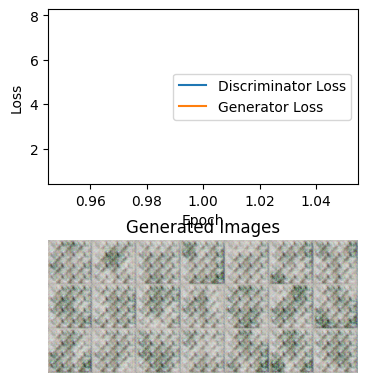

#1: loss_D 0.759, loss_G 7.914


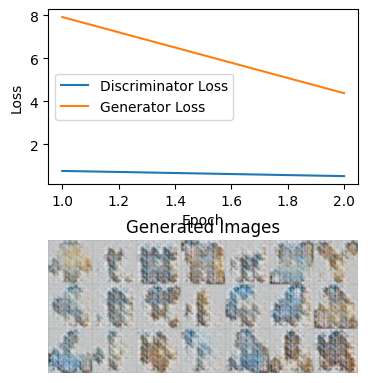

#2: loss_D 0.518, loss_G 4.373


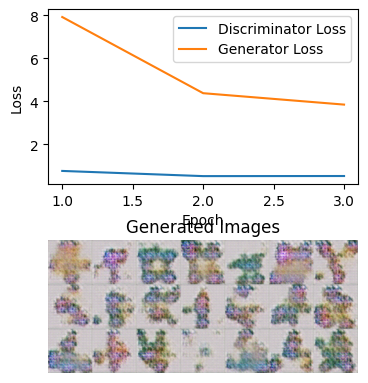

#3: loss_D 0.523, loss_G 3.843


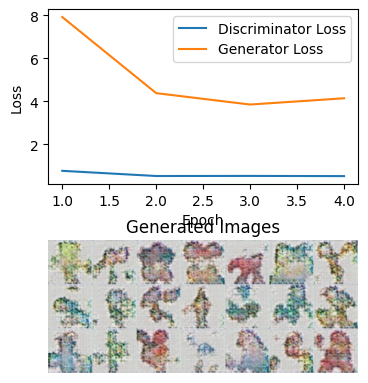

#4: loss_D 0.513, loss_G 4.134


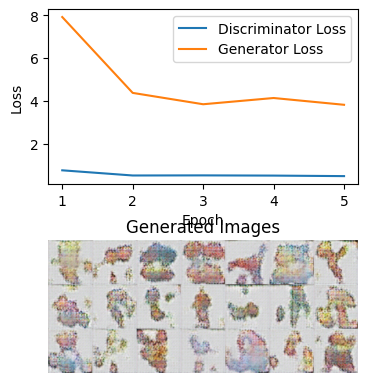

#5: loss_D 0.488, loss_G 3.818


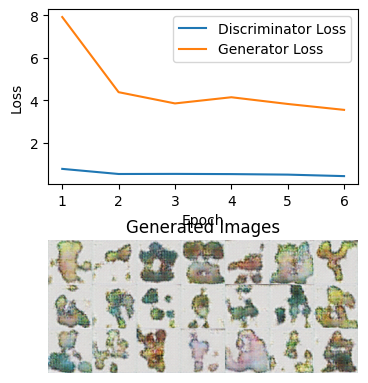

#6: loss_D 0.418, loss_G 3.540


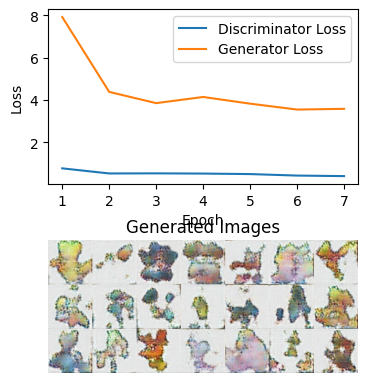

#7: loss_D 0.392, loss_G 3.573


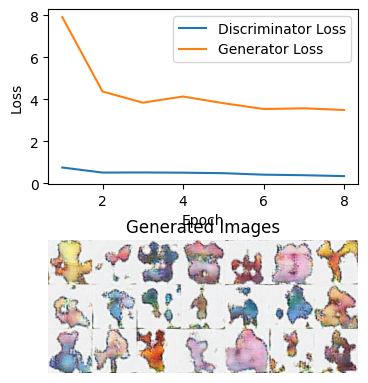

#8: loss_D 0.349, loss_G 3.495


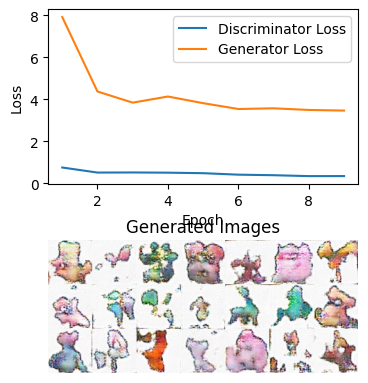

#9: loss_D 0.350, loss_G 3.466


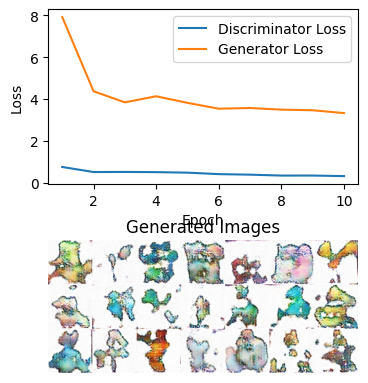

#10: loss_D 0.323, loss_G 3.329


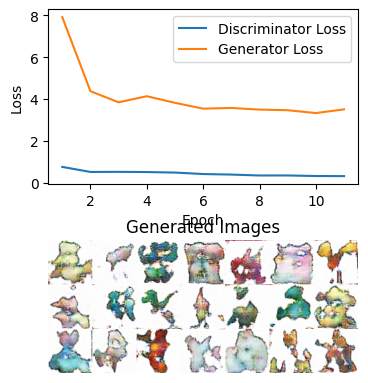

#11: loss_D 0.319, loss_G 3.506


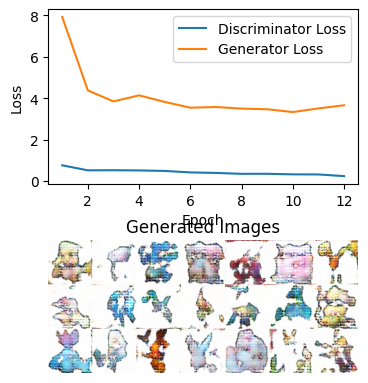

#12: loss_D 0.239, loss_G 3.656


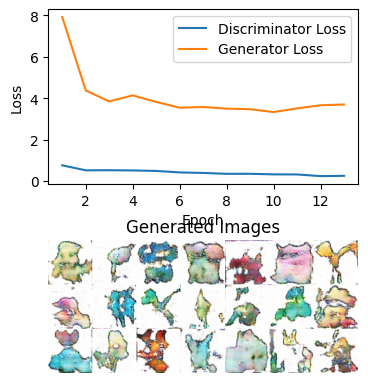

#13: loss_D 0.252, loss_G 3.694


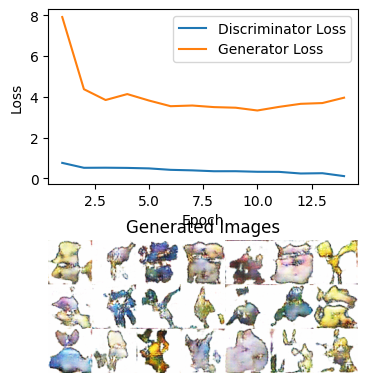

#14: loss_D 0.110, loss_G 3.957


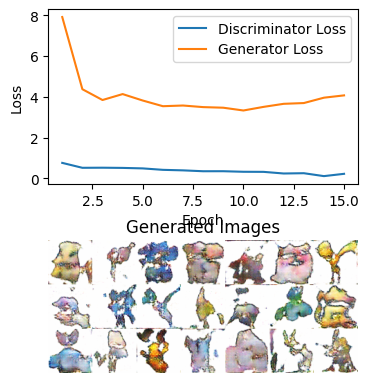

#15: loss_D 0.223, loss_G 4.070


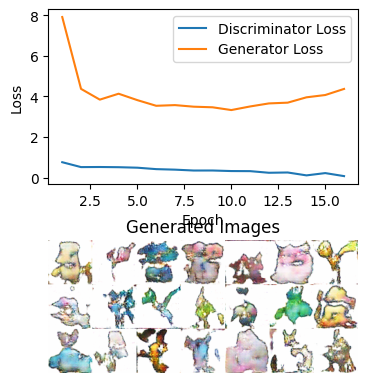

#16: loss_D 0.074, loss_G 4.371


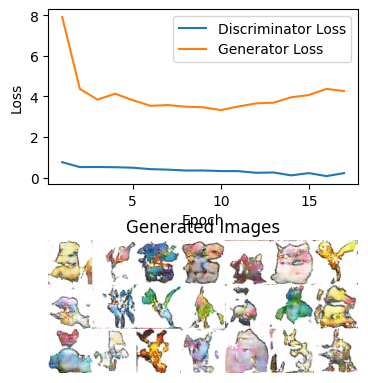

#17: loss_D 0.223, loss_G 4.267


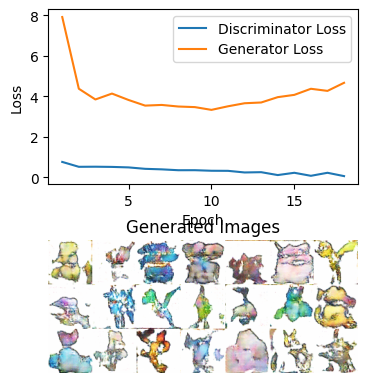

#18: loss_D 0.058, loss_G 4.666


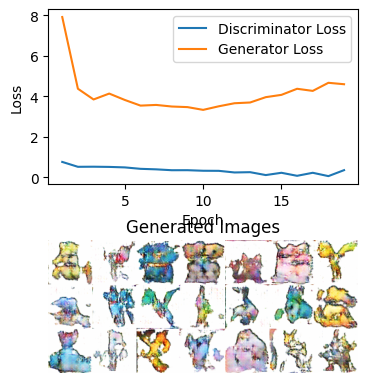

#19: loss_D 0.353, loss_G 4.595


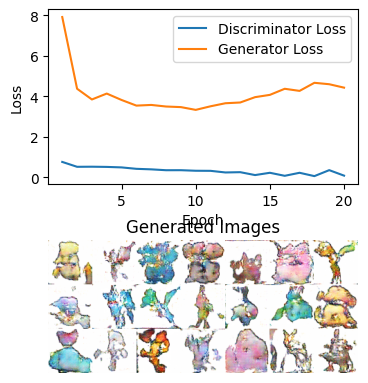

#20: loss_D 0.082, loss_G 4.427
loss_D 0.082, loss_G 4.427, 653.0 examples/sec on cuda


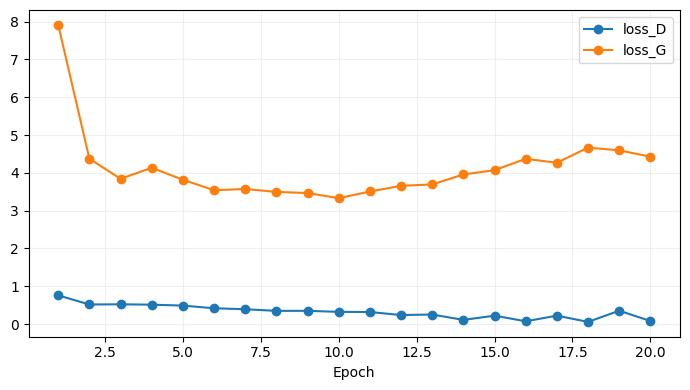

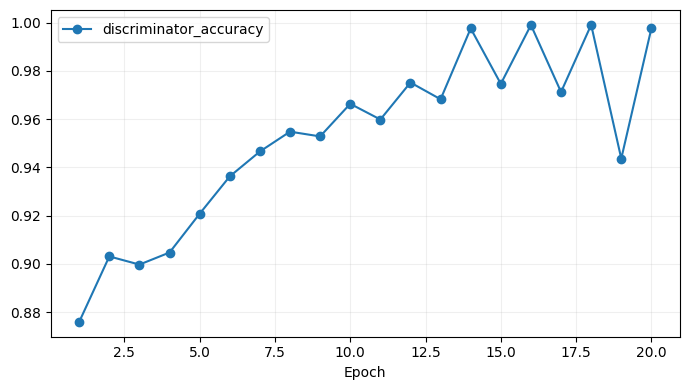

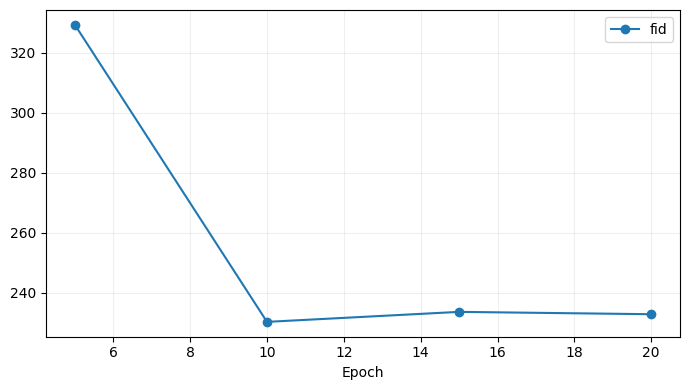

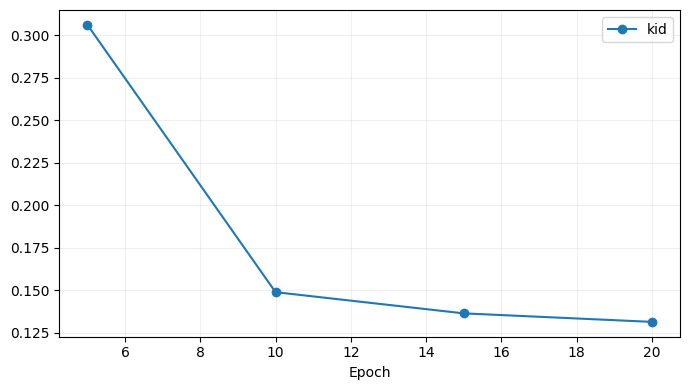

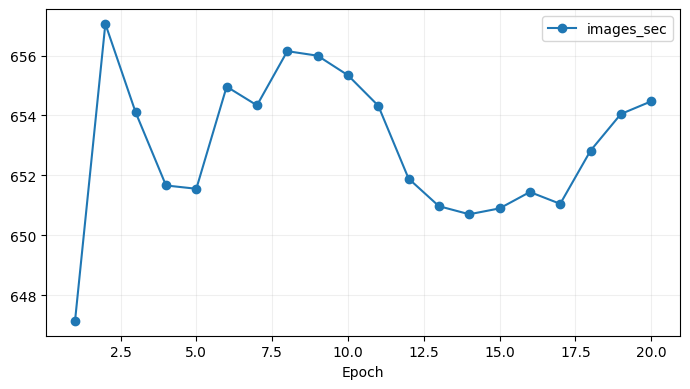

In [20]:
latent_dim = 100
lr = 2e-4
num_epochs = 20
gan_history = train(net_D, net_G, data_iter, num_epochs, lr, latent_dim)
plot_history(gan_history,[['loss_D','loss_G'],['discriminator_accuracy'],['fid'],['kid'],['images_sec']], 'gan')

In [21]:
torch.save({"vae": vae.state_dict(), "generator": net_G.state_dict(), "discriminator": net_D.state_dict(), "vae_latent_dim": vae.latent_dim, "gan_latent_dim": latent_dim}, "pokemon_models.pth")
print("Saved pokemon_models.pth")

Saved pokemon_models.pth


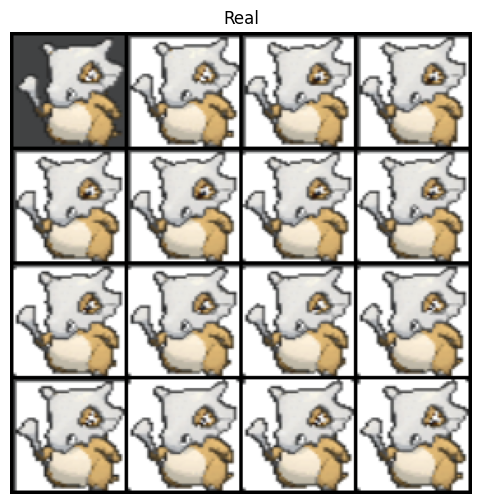

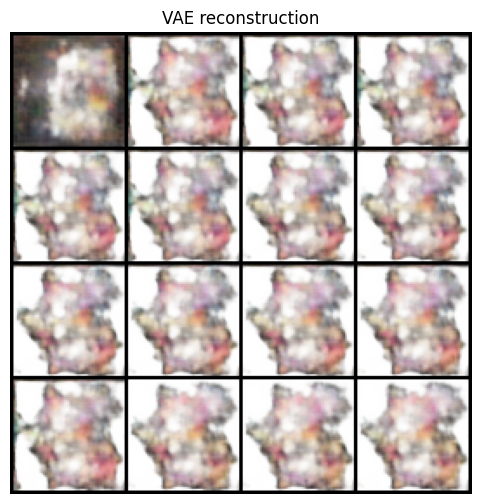

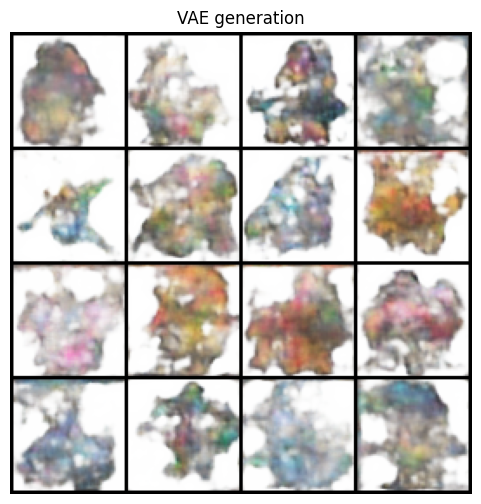

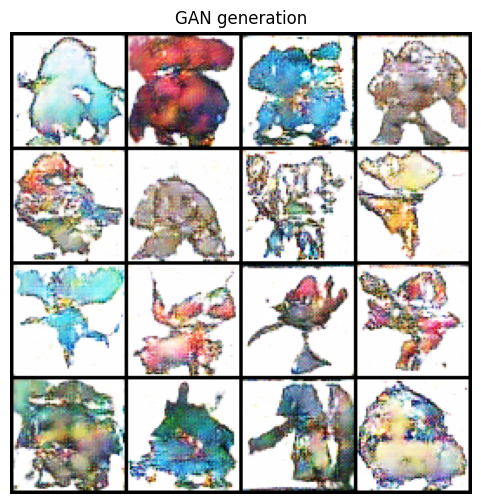

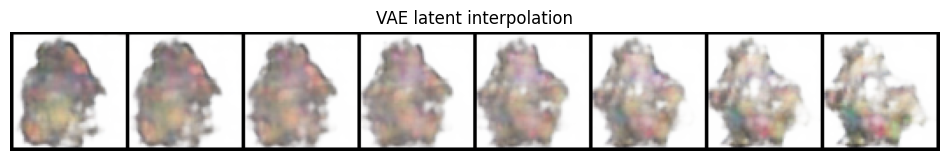

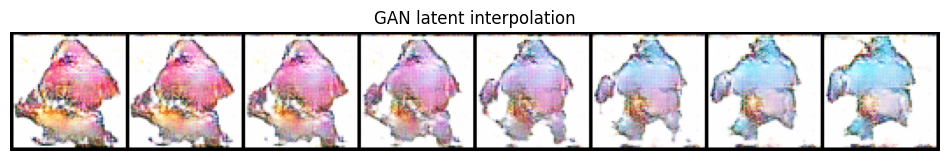

,model,FID,KID,KID std,training seconds,images/sec,MSE,PSNR,SSIM,D train accuracy
0,VAE,308.573181,0.259301,0.014957,274.713777,2363.842132,0.033014,15.084228,0.430009,NaN
1,GAN,232.914902,0.131353,0.006888,994.399616,653.037259,NaN,NaN,NaN,0.997675


In [22]:
# Side-by-side comparison and deterministic VAE reconstructions.
from torchvision.utils import make_grid
vae.eval(); net_G.eval()
with torch.no_grad():
    real = ref_images[:16].to(device)
    reconstructed = vae.decode(vae.encode(real)[0])
    generated_vae = vae.decode(vae_z[:16])
    generated_gan = net_G(torch.randn(16,latent_dim,1,1,device=device)).mul(.5).add(.5)
    for name, imgs in [('Real',real),('VAE reconstruction',reconstructed),('VAE generation',generated_vae),('GAN generation',generated_gan)]:
        fig, ax = plt.subplots(figsize=(6,6)); ax.imshow(make_grid(imgs.cpu(),nrow=4).permute(1,2,0).clamp(0,1)); ax.set_title(name); ax.axis('off'); fig.savefig(OUT/(name.replace(' ','_')+'.png'),dpi=150); plt.show(); plt.close(fig)
    alpha = torch.linspace(0,1,8,device=device).view(8,1)
    zv = (1-alpha)*vae_z[0]+alpha*vae_z[1]
    zg = torch.randn(2,latent_dim,device=device)
    zg = ((1-alpha)*zg[0]+alpha*zg[1]).view(8,latent_dim,1,1)
    for name, imgs in [('VAE',vae.decode(zv)),('GAN',net_G(zg).mul(.5).add(.5))]:
        fig,ax=plt.subplots(figsize=(12,2)); ax.imshow(make_grid(imgs.cpu(),nrow=8).permute(1,2,0).clamp(0,1)); ax.set_title(name+' latent interpolation'); ax.axis('off'); fig.savefig(OUT/(name+'_interpolation.png'),dpi=150); plt.show(); plt.close(fig)
summary = pd.DataFrame([{'model':name, 'FID':h.fid.dropna().iloc[-1], 'KID':h.kid.dropna().iloc[-1], 'KID std':h.kid_std.dropna().iloc[-1], 'training seconds':h.train_seconds.sum(), 'images/sec':len(train_idx)*len(h)/h.train_seconds.sum()} for name,h in [('VAE',vae_history),('GAN',gan_history)]])
summary.loc[0,['MSE','PSNR','SSIM']] = vae_history.iloc[-1][['mse','psnr','ssim']].values
summary.loc[1,'D train accuracy'] = gan_history.discriminator_accuracy.iloc[-1]
summary.to_csv(OUT/'summary.csv',index=False); display(summary)
